In [184]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os


In [185]:
data = pd.read_csv("données/LucasBenjamin_5ae9cde00335e200019e9eed.csv", skiprows=1, index_col=3)

## Filtering du dataframe pour 1 sujet

In [186]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)


In [187]:
df_filtered

,trial_rt,presented_angles,stimulus_rotations,final_angle,target,score
0,2305.0,"[186.3297408056, 172.4988425288, 115.6656248854]","[-45.0, -45.0, 45.0]",-24.646771,143.138643,6
1,1958.0,"[98.0630303799, 193.2006295208, 49.6275131924,...","[45.0, -45.0, 45.0, -45.0, 0.0, -45.0, -45.0]",-13.958290,132.662918,0
2,2380.0,"[34.0026636518, 78.5751250026, 144.2219944684,...","[45.0, 45.0, 0.0, 0.0, 0.0]",146.390631,130.568813,6
3,1969.0,"[86.8257191556, 137.819327054, 157.3072000846]","[0.0, -45.0, -45.0]",52.776429,97.281009,0
4,1735.0,"[99.1813592646, 91.1827684021, -22.5187808445,...","[-45.0, -45.0, 45.0, 0.0, 45.0, -45.0, -45.0]",209.237852,31.195139,10
...,...,...,...,...,...,...
195,2426.0,[218.4099821053],[-45.0],-9.130176,173.409982,10
196,2508.0,[195.9147529961],[0.0],15.718573,15.914753,10
197,1822.0,"[159.3437590786, 153.8696178772, 90.66764952, ...","[-45.0, -45.0, 0.0, 0.0, 0.0]",-79.343152,105.643527,10
198,1814.0,[74.993424937],[-45.0],-59.349332,29.993425,0


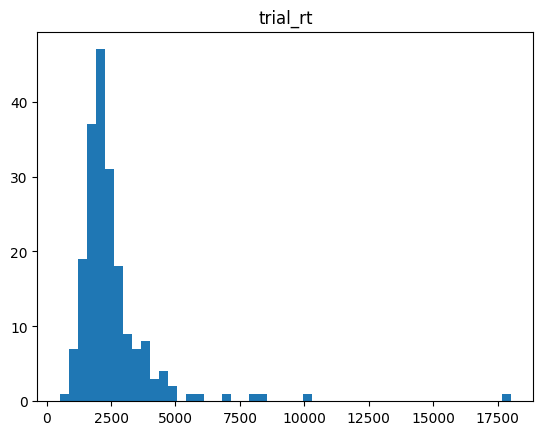

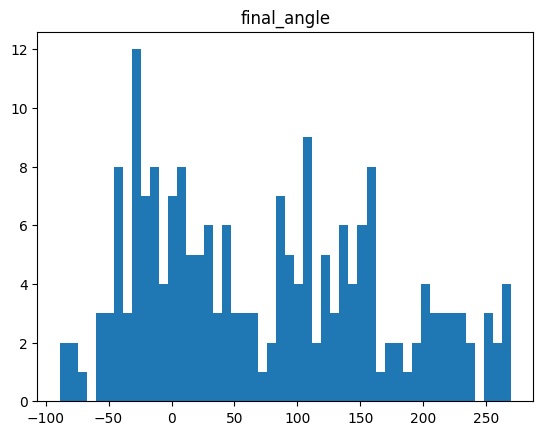

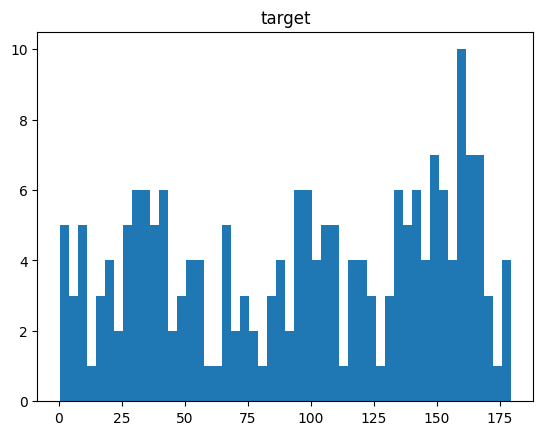

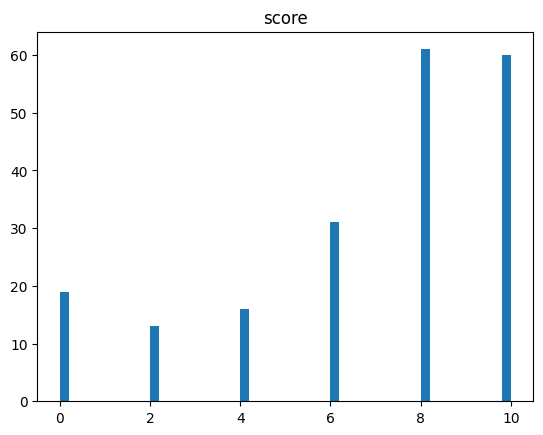

In [188]:
exclude = ['colonne_a_exclure1', 'colonne_a_exclure2']

for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

## Filtrage des données pour tous

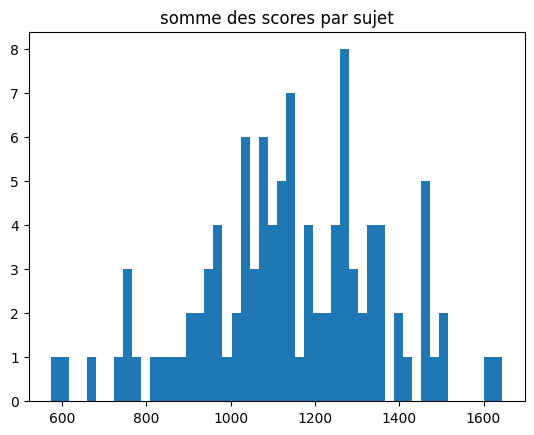

In [206]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

score_sum = []
for dfs in dfs :     
    df_filtered = dfs[dfs["stimulus_rotations"].notna()]
    df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
    df_filtered.reset_index(drop=True, inplace=True)
    df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df_filtered['score'] = df_filtered['score'].astype(int)
    score_sum.append(df_filtered["score"].sum())


score_sum

plt.hist(score_sum, bins=50)
plt.title("somme des scores par sujet")
plt.show()
